# E02 · Why a lens computes a Fourier transform

A lens sorts plane waves into focal spots. A second lens turns that spectrum back into an image—and lets you edit it along the way.

<!-- course-motivation:start -->
## Why learn this?

**Can you filter an image before the camera sees it?**

Suppose you want to suppress fine texture, emphasize boundaries, or reveal a nearly invisible transparent object. A lens gives you access to the spatial frequencies of the field, so a mask placed between two lenses can change which features reach the camera.

**What you gain:** Choose where to place a filter and predict its effect on amplitude and phase objects, including which image detail the filter removes.
<!-- course-motivation:end -->

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Complex amplitudes and phase:** Follow a position-dependent phase multiplying a complex field. Used here: A thin lens changes the wavefront before free-space propagation. [Review: MIT OCW · Complex Arithmetic and Exponentials](https://ocw.mit.edu/courses/18-03sc-differential-equations-fall-2011/pages/unit-i-first-order-differential-equations/complex-arithmetic-and-exponentials/). Read the notes on Euler's formula, polar form, multiplication, and complex conjugation. The differential-equation applications can wait.
- **Fourier transforms and convolution:** Recognize spatial frequency, the Fourier shift property, and two successive transforms. Used here: These connect illumination direction, focal-plane position, and the inverted 4f image. [Review: TU Delft · Fourier analysis](https://qiweb.tudelft.nl/aoi/fourieranalysis/fourieranalysis/). Use §4.1 for the transform pair, then §4.2.1–4.2.4 for linearity, scaling, shifts, and convolution. Consult §4.2.7 for two successive transforms.

**Python preparation:** Use 2D FFTs and distinguish a frequency-bin coordinate from a focal-plane coordinate.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.
- [NumPy · Discrete Fourier Transform](https://numpy.org/doc/stable/reference/routines.fft.html) — Read Implementation details and Normalization; look up fftfreq, fftshift, and ifftshift as they appear in the notebook.

**Developed here:** Connect a lens's Fourier plane to spatial filtering and phase contrast.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Convert transverse spatial frequency into a focal-plane coordinate.
- Explain why two Fourier transforms invert an image.
- Predict how Fourier-plane masks change amplitude and phase objects.

**Model:** Coherent monochromatic scalar illumination, ideal paraxial lenses, and thin Fourier masks. The focal-spot panel uses a Gaussian entrance field. The 4f panel is a periodic sampled field; no aberrations, finite detector pixels, or noise are included.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e02_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.11.7 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2


## 1 · Put physical units on a Fourier axis

A paraxial lens maps spatial frequency $f_x$ to $x_f=\lambda f f_x$.
A finite entrance field makes a finite-width spot. Tilting it changes the position,
while increasing focal length stretches the entire focal-plane coordinate scale.
**Predict:** double f before rerunning. Which plotted distance should double?

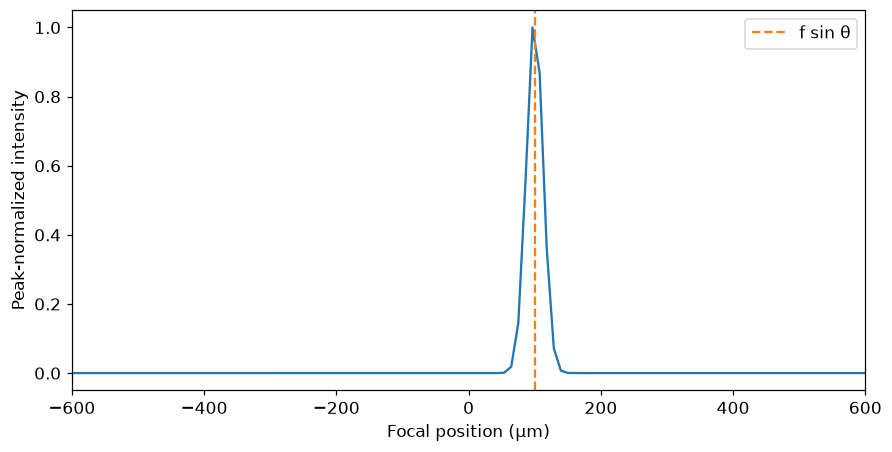

Predicted / sampled peak: 99.99833334166665 96.6796875 μm; focal sample spacing: 10.7421875


In [2]:
wavelength, focal_length = .55, 10000.  # μm
tilt = .01  # rad
n,dx = 512,1.
x=(np.arange(n)-n//2)*dx
field=np.exp(-(x/70)**2)*np.exp(2j*np.pi*np.sin(tilt)*x/wavelength)
F=lambda u:np.fft.fftshift(np.fft.fftn(np.fft.ifftshift(u),norm="ortho"))
FH=lambda u:np.fft.fftshift(np.fft.ifftn(np.fft.ifftshift(u),norm="ortho"))
frequency=np.fft.fftshift(np.fft.fftfreq(n,dx))
focal_x=wavelength*focal_length*frequency
spot=abs(F(field))**2
prediction=focal_length*np.sin(tilt)
peak_position=focal_x[np.argmax(spot)]
assert abs(peak_position-prediction)<=abs(focal_x[1]-focal_x[0])/2+1e-9
assert abs(np.sum(spot)/np.sum(abs(field)**2)-1)<1e-12
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(focal_x,spot/spot.max());ax.axvline(prediction,color="tab:orange",ls="--",label="f sin θ")
ax.set(xlim=(-600,600),xlabel="Focal position (μm)",ylabel="Peak-normalized intensity");ax.legend()
show(fig,"01-directions-to-positions")
print("Predicted / sampled peak:",prediction,peak_position,"μm; focal sample spacing:",focal_x[1]-focal_x[0])

## 2 · A 4f system transforms twice

The first lens transforms the complex field, a mask multiplies it, and the second lens
transforms again. Two forward transforms reverse the periodic spatial indices.
For coherent illumination, filter the field first and square only at the detector.

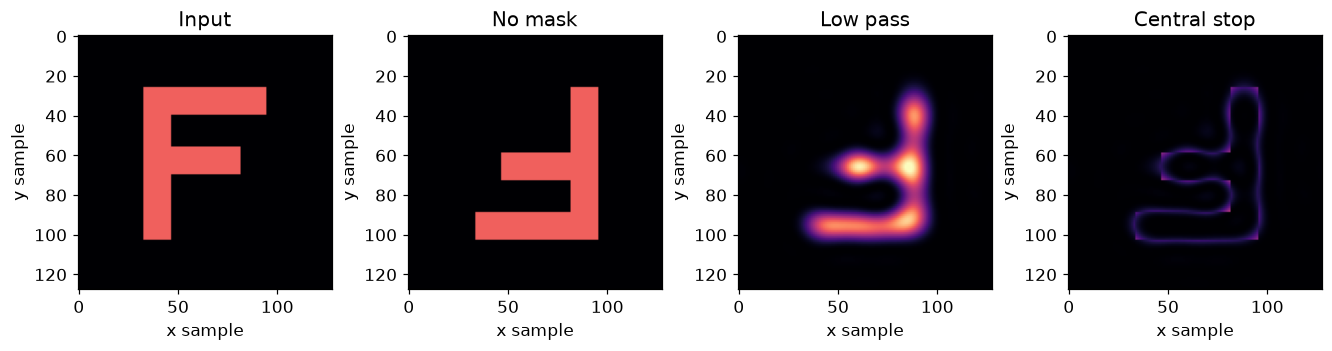

4f reversal assertion passed.


In [3]:
n=128
yy,xx=np.mgrid[:n,:n]/n
letter=((xx>.25)&(xx<.36)&(yy>.2)&(yy<.8))|((xx>.25)&(xx<.74)&(yy>.2)&(yy<.31))|((xx>.25)&(xx<.64)&(yy>.43)&(yy<.54))
object_field=letter.astype(complex)
f=np.fft.fftshift(np.fft.fftfreq(n));FX,FY=np.meshgrid(f,f);radius=np.hypot(FX,FY)
masks={"No mask":np.ones((n,n)),"Low pass":radius<.04,"Central stop":radius>.04}
index=(-np.arange(n))%n
expected=object_field[np.ix_(index,index)]
assert np.max(abs(F(F(object_field))-expected))<1e-12
fig,ax=plt.subplots(1,4,figsize=(12,3.6))
ax[0].imshow(abs(object_field)**2,vmin=0,vmax=1.5,cmap="magma");ax[0].set_title("Input")
for a,(name,mask) in zip(ax[1:],masks.items()):
    image=F(mask*F(object_field))
    a.imshow(abs(image)**2,vmin=0,vmax=1.5,cmap="magma");a.set_title(name)
for a in ax:a.set(xlabel="x sample",ylabel="y sample")
show(fig,"02-fourier-masks")
print("4f reversal assertion passed.")

## 3 · Rotate the background of a phase object

A weak phase object has $U \approx 1+i\phi$. A small phase disk changes the relative
phase of the central background and scattered components. This can reveal structure,
but the finite disk also modifies low-frequency scattering: it is not an exact phase map.

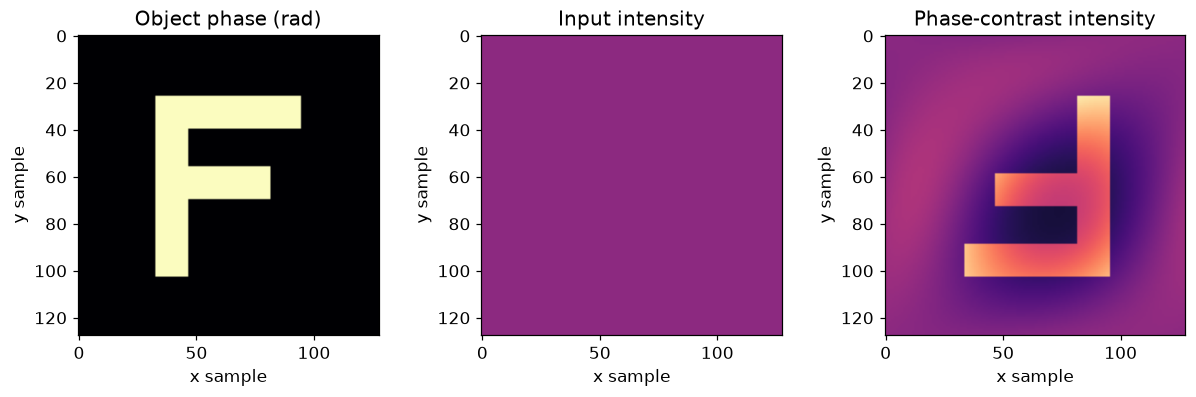

In [4]:
phase_object=np.exp(.65j*letter)
phase_disk=np.exp(1j*np.pi/2*(radius<1.5/n))
revealed=F(phase_disk*F(phase_object))
assert np.ptp(abs(phase_object)**2)<1e-12
assert np.ptp(abs(revealed)**2)>.1
fig,ax=plt.subplots(1,3,figsize=(11,3.5))
for a,v,title in zip(ax,[.65*letter,abs(phase_object)**2,abs(revealed)**2],["Object phase (rad)","Input intensity","Phase-contrast intensity"]):
    a.imshow(v,cmap="magma",vmin=0,vmax=2.5 if "intensity" in title.lower() else .65)
    a.set(title=title,xlabel="x sample",ylabel="y sample")
show(fig,"03-phase-contrast")

## Optional extension · Propagate from the front focal plane to the back focal plane

Compare the same input field in two physical positions. Against the lens, its path is
$U\to L\to P_f$. One focal length before the lens, its path is $U\to P_f\to L\to P_f$.
Here $L(x)=\exp[-i\pi x^2/(\lambda f)]$ and the one-dimensional Fresnel operator is
$P_f[U](x')=A_f\int U(x)\exp[i\pi(x'-x)^2/(\lambda f)]\,dx$,
with $A_f=\exp(ikf)/\sqrt{i\lambda f}$ and $k=2\pi/\lambda$.
All lengths below are in micrometres. The lens is ideal, paraxial and has no limiting stop.

Define $\widehat U(f_x)=\int U(x)\exp(-2\pi i f_xx)\,dx$ and use $x_f=\lambda f f_x$.
The against-lens output is $A_f\exp[i\pi x_f^2/(\lambda f)]\widehat U(f_x)$.
The front-to-back output is $\exp(ikf)A_f\widehat U(f_x)$: only a constant phase remains.
We compute every propagation leg by direct quadrature, then compare the complex fields
with these predictions. The known prefactors are retained; no fitted phase is removed.
**Predict:** can the two focal intensities agree while the complex fields differ?

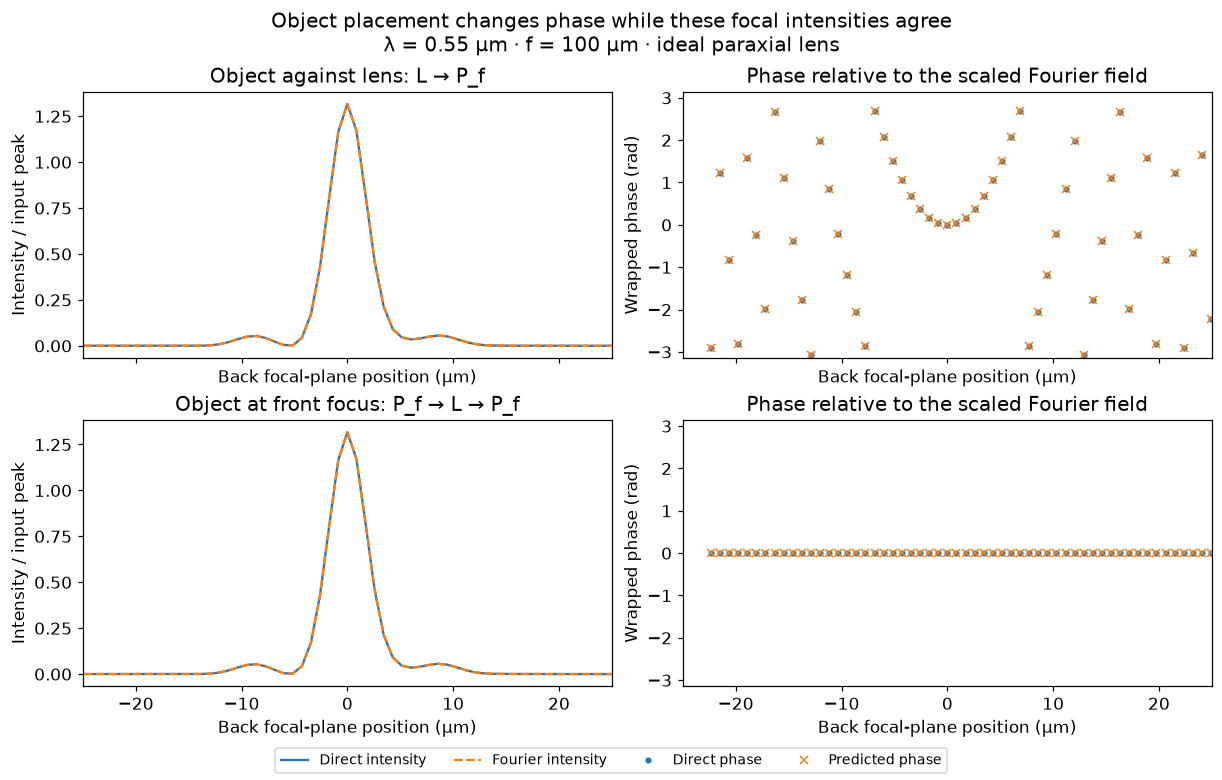

Front-to-back complex-field errors for lens half-widths 32, 64, 102.4 μm: [np.float64(0.00032556261047696916), np.float64(7.255115986749452e-10), np.float64(1.0902466442860853e-14)]
Halving lens-plane spacing, relative field change: 1.293704447462849e-14
Halving input spacing, relative field change: 4.723791444239503e-15
Against-lens / front-to-back complex-field relative errors: 3.1905152107199295e-15 6.879810932034997e-15
Against-lens field error if the output chirp is omitted: 0.5060926931331187


In [5]:
size,spacing,f_lens,lam=512,.125,100.,.55
xin=(np.arange(size)-size//2)*spacing
input_field=np.exp(-(xin/5)**2)*np.exp(.4j*np.sin(xin))
fx=np.fft.fftshift(np.fft.fftfreq(size,spacing))
central=slice(size//2-64,size//2+64)
xout=lam*f_lens*fx[central]
k=2*np.pi/lam
A_f=np.exp(1j*k*f_lens)/np.sqrt(1j*lam*f_lens)

def fresnel_step(field,source_x,target_x):
    """Direct 1D Fresnel quadrature over distance f_lens, including its prefactor."""
    source_dx=source_x[1]-source_x[0]
    kernel=np.exp(1j*k*(target_x[:,None]-source_x[None,:])**2/(2*f_lens))
    return A_f*(kernel@field)*source_dx

def front_to_back(lens_half_width,lens_dx):
    # This window approximates an unbounded lens plane; enlarge it to check truncation.
    lens_x=np.arange(-lens_half_width,lens_half_width,lens_dx)
    at_lens=fresnel_step(input_field,xin,lens_x)
    after_lens=at_lens*np.exp(-1j*k*lens_x*lens_x/(2*f_lens))
    return fresnel_step(after_lens,lens_x,xout)

fourier=np.fft.fftshift(np.fft.fft(np.fft.ifftshift(input_field)))[central]*spacing
output_chirp=np.exp(1j*k*xout*xout/(2*f_lens))
flat_against=A_f*fourier
expected_against=flat_against*output_chirp
expected_front=np.exp(1j*k*f_lens)*A_f*fourier
against=fresnel_step(input_field*np.exp(-1j*k*xin*xin/(2*f_lens)),xin,xout)

# Vary the intermediate window independently of its sampling; then halve the spacing.
window_errors=[]
for half_width in [32.,64.,102.4]:
    trial=front_to_back(half_width,.2)
    window_errors.append(np.linalg.norm(trial-expected_front)/np.linalg.norm(expected_front))
front=front_to_back(102.4,.1)
refinement=np.linalg.norm(front-trial)/np.linalg.norm(front)
# Refine the input sampling too, preserving its physical window and the output positions.
finer_x=(np.arange(2*size)-size)*(spacing/2)
finer_input=np.exp(-(finer_x/5)**2)*np.exp(.4j*np.sin(finer_x))
lens_x=np.arange(-102.4,102.4,.1)
finer_at_lens=fresnel_step(finer_input,finer_x,lens_x)
finer_front=fresnel_step(finer_at_lens*np.exp(-1j*k*lens_x*lens_x/(2*f_lens)),lens_x,xout)
input_refinement=np.linalg.norm(finer_front-front)/np.linalg.norm(front)
front_error=np.linalg.norm(front-expected_front)/np.linalg.norm(expected_front)
against_error=np.linalg.norm(against-expected_against)/np.linalg.norm(expected_against)
missing_chirp_error=np.linalg.norm(against-flat_against)/np.linalg.norm(flat_against)
assert window_errors[2]<window_errors[1]<window_errors[0]
assert max(front_error,against_error,refinement,input_refinement)<1e-10
assert missing_chirp_error>.1
assert np.linalg.norm(abs(front)**2-abs(against)**2)/np.linalg.norm(abs(front)**2)<1e-10

fig,ax=plt.subplots(2,2,figsize=(11,7),sharex=True,layout="constrained")
bright=abs(fourier)>1e-3*abs(fourier).max()
for row,(actual,flat,title) in enumerate([
    (against,flat_against,"Object against lens: L → P_f"),
    (front,expected_front,"Object at front focus: P_f → L → P_f")]):
    ax[row,0].plot(xout,abs(actual)**2,label="Direct propagation")
    ax[row,0].plot(xout,abs(flat)**2,"--",label="Scaled Fourier intensity")
    ax[row,0].set(title=title,ylabel="Intensity / input peak")
    residual=np.angle(actual*np.conj(flat))
    ax[row,1].plot(xout[bright],residual[bright],"o",ms=3,label="Computed phase difference")
    prediction=np.angle(output_chirp) if row==0 else np.zeros_like(xout)
    ax[row,1].plot(xout[bright],prediction[bright],"x",ms=5,label="Output chirp" if row==0 else "Zero coordinate phase")
    ax[row,1].set(title="Phase relative to the scaled Fourier field",ylabel="Wrapped phase (rad)",ylim=(-np.pi,np.pi))
for a in ax.flat:a.set(xlim=(-25,25),xlabel="Back focal-plane position (μm)")
fig.legend([*ax[0,0].get_lines(),*ax[0,1].get_lines()],
           ["Direct intensity","Fourier intensity","Direct phase","Predicted phase"],
           loc="outside lower center",ncol=4,fontsize=9)
fig.suptitle(f"Object placement changes phase while these focal intensities agree\nλ = {lam:g} μm · f = {f_lens:g} μm · ideal paraxial lens",fontsize=13)
show(fig,"04-fresnel-check")
print("Front-to-back complex-field errors for lens half-widths 32, 64, 102.4 μm:",window_errors)
print("Halving lens-plane spacing, relative field change:",refinement)
print("Halving input spacing, relative field change:",input_refinement)
print("Against-lens / front-to-back complex-field relative errors:",against_error,front_error)
print("Against-lens field error if the output chirp is omitted:",missing_chirp_error)

Agreement is for this sampled, scalar paraxial example. Window enlargement and grid
refinement check the numerical integral, not the accuracy of paraxial optics at large
angles. Phase is plotted only where Fourier amplitude exceeds 0.1% of its peak, because
phase at a dark sample is not a useful comparison. The errors above use the full complex
arrays on the common output grid, including the dark samples and known constant phases.

## A short lab report

**1. Calibrate the Fourier plane.** Predict the focal coordinate of a known spatial frequency for two focal lengths.

**2. Compare three masks.** Save unfiltered, low-pass, and central-stop images with the same intensity scale.

**3. Make phase visible.** Compare a weak phase object before and after a central π/2 phase shift.

### Worked reasoning

**Calibrate the Fourier plane.** Use x_f = λf fₓ with consistent units. The frequency grid and physical focal grid are not the same axis.

**Compare three masks.** The mask acts on the complex field spectrum. Squaring after filtering makes coherent image formation nonlinear in input intensity.

**Make phase visible.** The small scattered field interferes differently with the rotated background. Finite disk size and strong phase shifts limit the weak-object interpretation.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [MIT OpenCourseWare · Spatial filtering and lens transforms](https://ocw.mit.edu/courses/2-71-optics-spring-2009/resources/lecture-18-spatial-filtering-lens-transfer-functions-transforms/)
- [TU Delft · Wavefield propagation](https://qiweb.tudelft.nl/aoi/wavefieldpropagation/wavefieldpropagation/)
- [NumPy · Fourier transforms and normalization](https://numpy.org/doc/stable/reference/routines.fft.html)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e02_figures.zip


/tmp/optics-notebooks-dtefv0te/E02/e02_figures.zip